# REPAIR-X — Experimental Evaluation & Reproducibility Notebook
### Risk-Aware Adaptive AI System for Autonomous Software Fault Diagnosis, Repair and Recovery

**HBTU Kanpur · B.Tech Information Technology · Semester-long Minor Project**

**Principal experiment:** 300 actual repair trials · 10 distinct controlled Python fault scenarios · 3 LLM providers · 10 repetitions per provider/case.

**Immutable source batch:** `2298cd6ffd37484789857f402f0a889c` · **Protocol:** `risk_aware_recovery_v2` · Recorded 15 November 2026.

> **Evidence boundary:** This notebook analyzes the actual logged trials supplied with the REPAIR-X source archive. It does not call LLM APIs, execute generated Python, or evaluate newly uploaded code. The curated CSV intentionally excludes generated patches, stack traces, prompts, credentials and private data. Charts and tables below are reproducibly generated from that file.

### Notebook outline
1. Data provenance, validation and metric definitions
2. Overall acceptance and per-provider evidence
3. Mean, median, percentiles and distribution of latency
4. Formatting corrections and repair-attempt efficiency
5. Risk and validation outcomes
6. Per-fault provider comparison
7. Graph exports and research limitations

## 1 · Load and validate the curated trial-level dataset

The CSV contains one row for each **trial**, not one row for each API call or test assertion. `attempt_count` counts actual repair attempts; `formatting_retries` counts formatting-correction requests, and is separate from repair attempts. `accepted_risk_score` describes the **accepted final patch**, not every intermediate rejected candidate.

The expected 300-trial count and source batch ID are recorded here so an accidental dataset replacement does not silently produce an incorrect figure.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import display, Markdown

BATCH_ID = "2298cd6ffd37484789857f402f0a889c"
PREFERRED_ORDER = ["groq", "openai", "gemini"]
DISPLAY_NAMES = {"groq": "Groq / Qwen", "openai": "OpenAI", "gemini": "Gemini"}

# Works with Jupyter launched inside notebooks/ or from the repository root.
candidates = [Path("data/evaluation_300_curated.csv"), Path("notebooks/data/evaluation_300_curated.csv")]
DATA = next((p for p in candidates if p.is_file()), None)
if DATA is None:
    raise FileNotFoundError("Missing notebooks/data/evaluation_300_curated.csv; preserve the ZIP folder structure.")
FIG_DIR = DATA.parent.parent / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA)
required = {"trial_index", "provider", "model", "case_id", "evaluation_status", "outcome", "elapsed_seconds", "attempt_count", "formatting_retries", "rejected_attempts", "high_risk_attempts", "accepted_risk_score", "accepted_risk_level", "accepted_visible_pass", "accepted_hidden_pass", "original_unchanged"}
assert required.issubset(df.columns), f"Missing dataset fields: {required - set(df.columns)}"
assert len(df) == 300 and df.trial_index.is_unique
assert set(df.provider) == set(PREFERRED_ORDER)
assert df.case_id.nunique() == 10
assert all(df.provider.value_counts().reindex(PREFERRED_ORDER) == 100)
assert df.elapsed_seconds.notna().all() and (df.elapsed_seconds >= 0).all()
assert df.evaluation_status.fillna("UNKNOWN").isin(["ACCEPTED", "ABSTAINED", "INFRASTRUCTURE_ERROR"]).all()
assert df.attempt_count.ge(0).all()
print("SOURCE BATCH:", BATCH_ID)
print("Dataset:", DATA.resolve())
print("Records:", len(df), "| Unique fault scenarios:", df.case_id.nunique())
print("Provider models:")
display(df.groupby("provider")["model"].unique().to_frame("model identifiers"))

SOURCE BATCH: 2298cd6ffd37484789857f402f0a889c
Dataset: D:\MINOR_PROJECT\REPAIR-X-starter\notebooks\data\evaluation_300_curated.csv
Records: 300 | Unique fault scenarios: 10
Provider models:


,model identifiers
provider,
gemini,[gemini-3.1-flash-lite]
groq,[qwen/qwen3.8-27b]
openai,[gpt-4.1-mini]


## 2 · Core evaluation metrics

**Acceptance rate (per provider):** accepted trials / all scheduled trials. **Evaluable success rate:** accepted / (accepted + abstained); infrastructure failures are excluded only from this second denominator. **Latency:** the time recorded in each trial (including the measured request/retry overhead). **P95 latency:** 95th percentile of observed trial durations. **Formatting corrections:** total formatting-retry requests, not unique failure cases.

In [2]:
def provider_statistics(frame):
    out = []
    for provider in PREFERRED_ORDER:
        g = frame[frame.provider == provider]
        e = g[g.evaluation_status != "INFRASTRUCTURE_ERROR"]
        accepted = int((g.evaluation_status == "ACCEPTED").sum())
        abstained = int((g.evaluation_status == "ABSTAINED").sum())
        infra = int((g.evaluation_status == "INFRASTRUCTURE_ERROR").sum())
        out.append({
            "provider": DISPLAY_NAMES[provider], "trials": len(g), "accepted": accepted,
            "abstained": abstained, "infrastructure_errors": infra,
            "acceptance_pct": 100*accepted/len(g),
            "evaluable_success_pct": 100*accepted/(accepted+abstained) if accepted+abstained else np.nan,
            "mean_s": e.elapsed_seconds.mean(), "median_s": e.elapsed_seconds.median(),
            "p95_s": e.elapsed_seconds.quantile(.95), "max_s": e.elapsed_seconds.max(),
            "std_s": e.elapsed_seconds.std(ddof=1),
            "mean_attempts": g.attempt_count.mean(),
            "total_repair_attempts": int(g.attempt_count.sum()),
            "multi_attempt_trials": int((g.attempt_count > 1).sum()),
            "formatting_corrections": int(g.formatting_retries.sum()),
            "trials_with_formatting_correction": int((g.formatting_retries > 0).sum()),
            "high_risk_rejected_candidates": int(g.high_risk_attempts.sum()),
        })
    return pd.DataFrame(out).set_index("provider")

stats = provider_statistics(df)
display(stats.round(3))
assert int(stats.accepted.sum()) == 300
assert int(stats.total_repair_attempts.sum()) == 301
assert stats.formatting_corrections.sum() == 66
assert int(stats.high_risk_rejected_candidates.sum()) == 1

,trials,accepted,abstained,infrastructure_errors,acceptance_pct,evaluable_success_pct,mean_s,median_s,p95_s,max_s,std_s,mean_attempts,total_repair_attempts,multi_attempt_trials,formatting_corrections,trials_with_formatting_correction,high_risk_rejected_candidates
provider,,,,,,,,,,,,,,,,,
Groq / Qwen,100,100,0,0,100.0,100.0,0.683,0.255,0.699,31.249,3.134,1.01,101,1,2,2,1
OpenAI,100,100,0,0,100.0,100.0,1.016,0.935,1.620,2.048,0.266,1.00,100,0,3,3,0
Gemini,100,100,0,0,100.0,100.0,7.602,2.498,31.806,64.497,10.987,1.00,100,0,61,61,0


## 3 · Trial outcomes and provider acceptance

The study produced **300 accepted trials out of 300** under the benchmark's acceptance criteria. This is a *ceiling result on a small controlled dataset*, not a general correctness guarantee. There were no recorded infrastructure-error outcomes in this principal batch (transient network retries did occur, but their complete counts were not retained in the exported trial-level data).

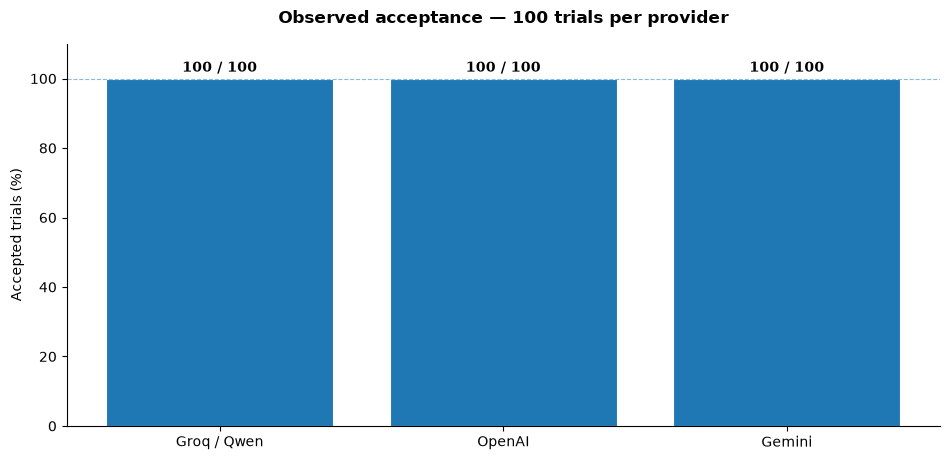

In [3]:
fig, ax = plt.subplots(figsize=(9.6,4.7))
labels = list(stats.index)
bars = ax.bar(labels, stats["acceptance_pct"], edgecolor="white", linewidth=.8)
ax.set_ylim(0,110); ax.set_ylabel("Accepted trials (%)")
ax.set_title("Observed acceptance — 100 trials per provider", fontweight="bold", pad=15)
ax.axhline(100, linewidth=.8, linestyle="--", alpha=.5)
for b in bars: ax.text(b.get_x()+b.get_width()/2, b.get_height()+2, "100 / 100", ha="center", fontsize=10, fontweight="bold")
ax.spines[["top","right"]].set_visible(False)
fig.tight_layout(); fig.savefig(FIG_DIR/"01_acceptance_by_provider.png",dpi=190,bbox_inches="tight")
plt.show()

## 4 · Latency: averages alone can conceal long tails

Mean latency includes slow outliers; median reflects a typical recorded trial. A boxplot on a logarithmic scale makes heavy-tailed behavior more legible than a single mean-value bar chart. These measurements are from one sequential experiment with provider/network/rate-limit effects and should **not** be interpreted as intrinsic model speed.

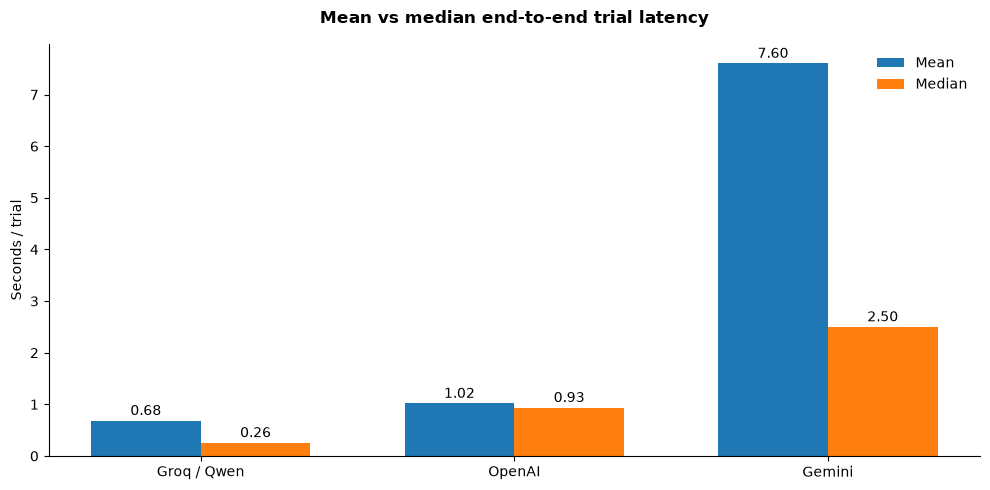

In [4]:
fig, ax = plt.subplots(figsize=(10,5))
x = np.arange(len(stats)); w = .35
b1=ax.bar(x-w/2,stats.mean_s,width=w,label="Mean")
b2=ax.bar(x+w/2,stats.median_s,width=w,label="Median")
for bars in (b1,b2):
    for b in bars: ax.text(b.get_x()+b.get_width()/2,b.get_height()+.11,f"{b.get_height():.2f}",ha="center",fontsize=10)
ax.set_xticks(x,stats.index); ax.set_ylabel("Seconds / trial"); ax.legend(frameon=False)
ax.set_title("Mean vs median end-to-end trial latency",fontweight="bold",pad=15)
ax.spines[["top","right"]].set_visible(False)
fig.tight_layout(); fig.savefig(FIG_DIR/"02_mean_median_latency.png",dpi=190,bbox_inches="tight")
plt.show()

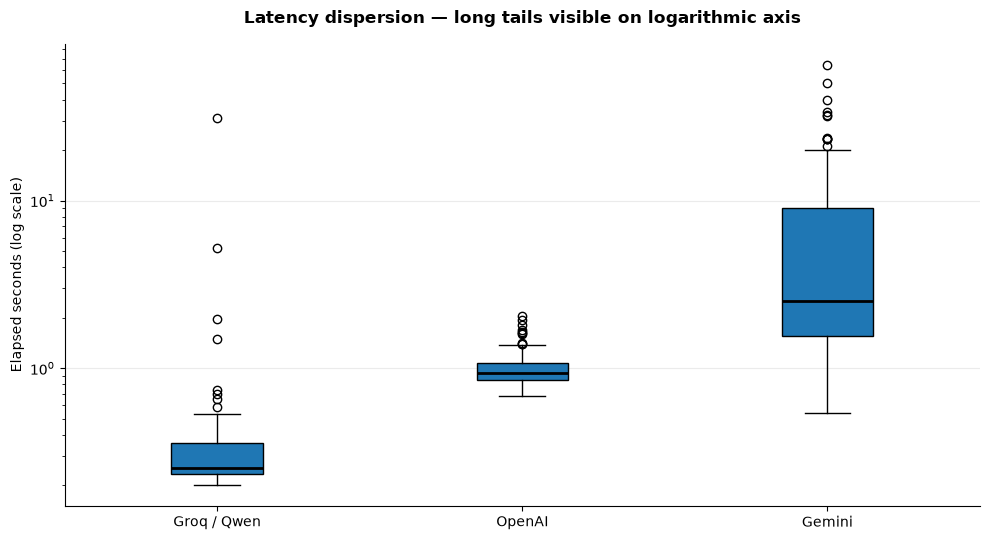

In [5]:
fig,ax=plt.subplots(figsize=(10,5.5))
values=[df.loc[df.provider==p,"elapsed_seconds"].values for p in PREFERRED_ORDER]
ax.boxplot(values,showfliers=True,patch_artist=True,medianprops={"color":"black","linewidth":2})
ax.set_xticks([1,2,3],[DISPLAY_NAMES[p] for p in PREFERRED_ORDER])
ax.set_yscale("log"); ax.set_ylabel("Elapsed seconds (log scale)")
ax.set_title("Latency dispersion — long tails visible on logarithmic axis",fontweight="bold",pad=15)
ax.grid(axis="y",alpha=.25); ax.spines[["top","right"]].set_visible(False)
fig.tight_layout(); fig.savefig(FIG_DIR/"03_latency_boxplot_log.png",dpi=190,bbox_inches="tight")
plt.show()

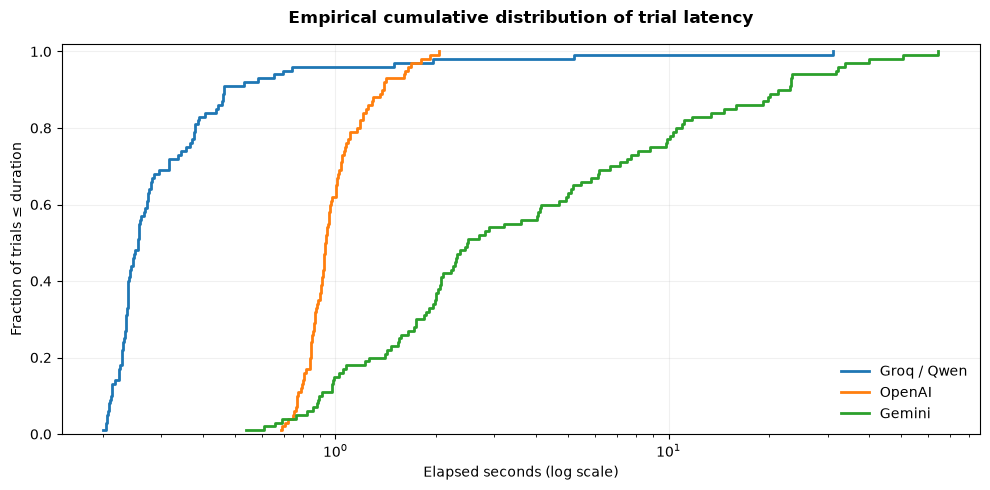

In [6]:
fig,ax=plt.subplots(figsize=(10,5))
for p in PREFERRED_ORDER:
    sorted_t=np.sort(df.loc[df.provider==p,"elapsed_seconds"].to_numpy())
    proportion=np.arange(1,len(sorted_t)+1)/len(sorted_t)
    ax.step(sorted_t,proportion,where="post",label=DISPLAY_NAMES[p],linewidth=2)
ax.set_xscale("log");ax.set_ylim(0,1.02)
ax.set_xlabel("Elapsed seconds (log scale)"); ax.set_ylabel("Fraction of trials ≤ duration")
ax.set_title("Empirical cumulative distribution of trial latency",fontweight="bold",pad=15)
ax.legend(loc="lower right",frameon=False);ax.grid(alpha=.18)
fig.tight_layout(); fig.savefig(FIG_DIR/"04_latency_ecdf.png",dpi=190,bbox_inches="tight")
plt.show()

## 5 · Formatting corrections and repair efficiency

A **formatting retry** is an extra request to obtain a structurally usable function body. It is not the same as a failed repair trial. A **repair attempt** is one candidate considered by the controller; the principal batch had 301 repair attempts for 300 accepted outcomes. Only one trial needed a second repair attempt.

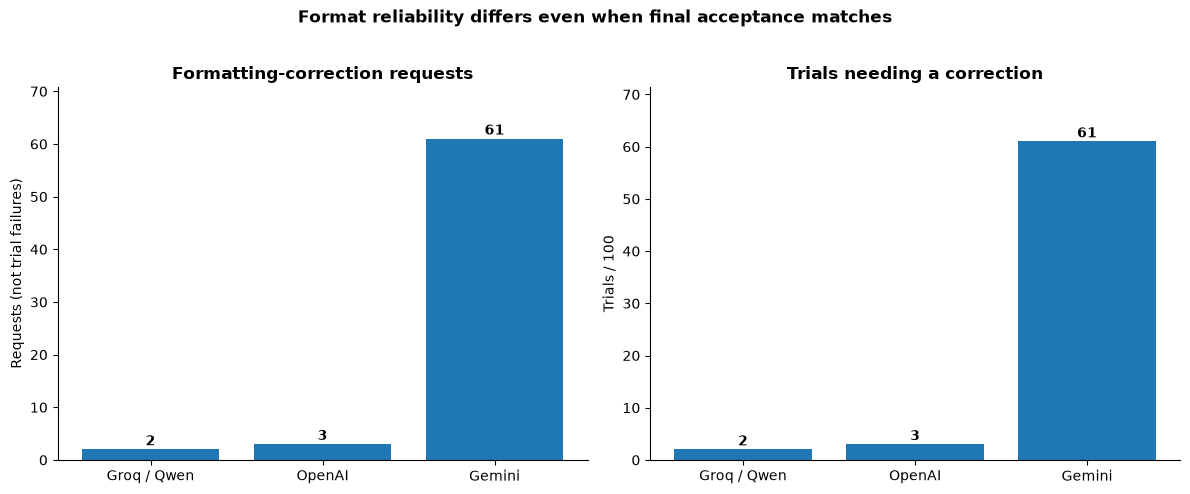

In [7]:
fig,axes=plt.subplots(1,2,figsize=(12,4.8))
names=stats.index.tolist()
bars=axes[0].bar(names,stats.formatting_corrections)
for b in bars:axes[0].text(b.get_x()+b.get_width()/2,b.get_height()+.8,f"{int(b.get_height())}",ha="center",fontweight="bold")
axes[0].set_title("Formatting-correction requests",fontweight="bold");axes[0].set_ylabel("Requests (not trial failures)")
axes[0].set_ylim(0,max(stats.formatting_corrections)*1.16)
bars2=axes[1].bar(names,stats.trials_with_formatting_correction)
for b in bars2:axes[1].text(b.get_x()+b.get_width()/2,b.get_height()+.8,f"{int(b.get_height())}",ha="center",fontweight="bold")
axes[1].set_title("Trials needing a correction",fontweight="bold");axes[1].set_ylabel("Trials / 100")
axes[1].set_ylim(0,max(stats.trials_with_formatting_correction)*1.17)
for ax in axes: ax.spines[["top","right"]].set_visible(False)
fig.suptitle("Format reliability differs even when final acceptance matches",fontweight="bold",y=1.02)
fig.tight_layout();fig.savefig(FIG_DIR/"05_formatting_corrections.png",dpi=190,bbox_inches="tight")
plt.show()

Repair-attempt distribution:


,trials
attempts,
1,299
2,1


Observed multi-attempt live recovery:


,trial_index,provider,case_id,attempt_count,rejected_attempts,high_risk_attempts,elapsed_seconds
39,40,groq,word_count,2,1,1,0.464


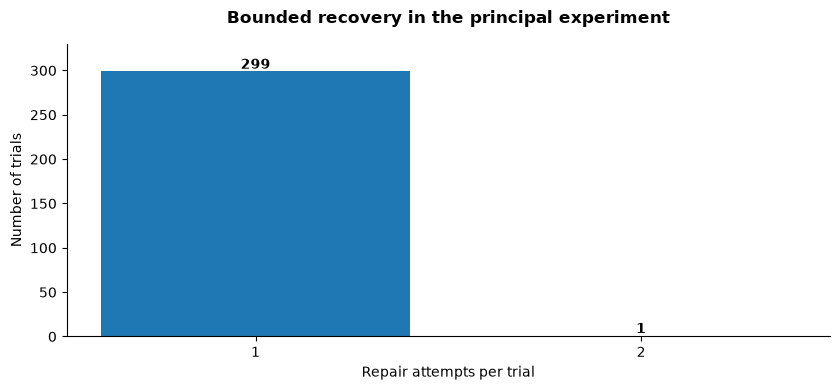

In [8]:
recovery = df[df.attempt_count>1]
print("Repair-attempt distribution:")
display(df.attempt_count.value_counts().sort_index().rename_axis("attempts").to_frame("trials"))
print("Observed multi-attempt live recovery:")
display(recovery[["trial_index","provider","case_id","attempt_count","rejected_attempts","high_risk_attempts","elapsed_seconds"]])
fig,ax=plt.subplots(figsize=(8.5,4))
counts=df.attempt_count.value_counts().sort_index(); b=ax.bar([str(i) for i in counts.index],counts.values)
for a in b:ax.text(a.get_x()+a.get_width()/2,a.get_height()+3,str(int(a.get_height())),ha="center",fontweight="bold")
ax.set_ylim(0,330);ax.set_xlabel("Repair attempts per trial");ax.set_ylabel("Number of trials")
ax.set_title("Bounded recovery in the principal experiment",fontweight="bold",pad=15)
ax.spines[["top","right"]].set_visible(False)
fig.tight_layout();fig.savefig(FIG_DIR/"06_repair_attempt_distribution.png",dpi=190,bbox_inches="tight")
plt.show()

## 6 · Risk screening and validation outcomes

Final accepted candidates were scored **LOW** by the implemented heuristic. The aggregate includes **one HIGH-risk candidate attempt** that was rejected before a later successful candidate. These are policy classifications, not measured security guarantees. “Visible/hidden pass” denotes the controller's final validation result on the accepted candidate; **hidden assertions participate in the acceptance gate**, so they cannot be described as an untouched external holdout.

Final accepted candidate risk levels:


,accepted candidates
accepted_risk_level,
LOW,300


Final accepted risk scores:


,accepted candidates
accepted_risk_score,
0,270
15,30


Pass flags on accepted candidates:


accepted_visible_pass       accepted_hidden_pass        \
                           sum count                  sum count   
provider                                                          
gemini                     100   100                  100   100   
groq                       100   100                  100   100   
openai                     100   100                  100   100   

         original_unchanged        
                        sum count  
provider                           
gemini                  100   100  
groq                    100   100  
openai                  100   100

Rejected HIGH risk candidate attempts: 1


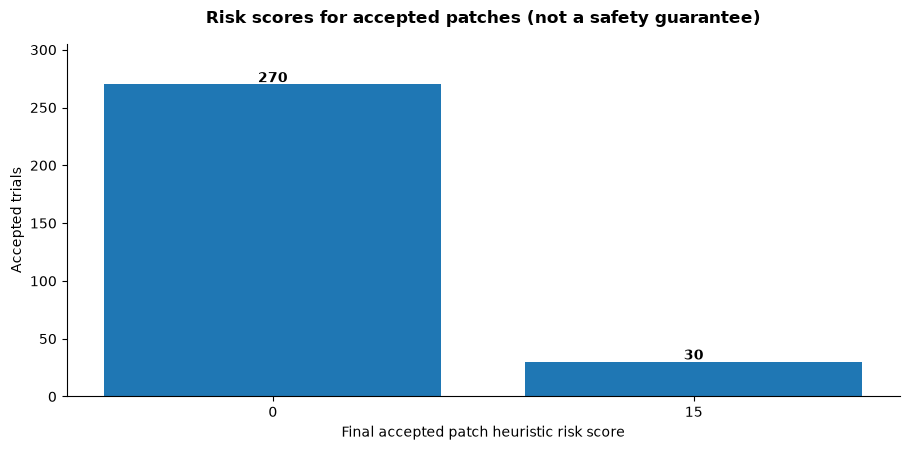

In [9]:
print("Final accepted candidate risk levels:")
display(df.accepted_risk_level.fillna("UNAVAILABLE").value_counts().to_frame("accepted candidates"))
print("Final accepted risk scores:")
display(df.accepted_risk_score.value_counts().sort_index().to_frame("accepted candidates"))
print("Pass flags on accepted candidates:")
display(df.groupby("provider")[["accepted_visible_pass","accepted_hidden_pass","original_unchanged"]].agg(["sum","count"]))
print("Rejected HIGH risk candidate attempts:", int(df.high_risk_attempts.sum()))
fig,ax=plt.subplots(figsize=(9.2,4.6))
score_ct=df.accepted_risk_score.value_counts().sort_index()
bars=ax.bar(score_ct.index.astype(str),score_ct.values)
for b in bars:ax.text(b.get_x()+b.get_width()/2,b.get_height()+2,str(int(b.get_height())),ha="center",fontweight="bold")
ax.set_xlabel("Final accepted patch heuristic risk score");ax.set_ylabel("Accepted trials")
ax.set_title("Risk scores for accepted patches (not a safety guarantee)",fontweight="bold",pad=15)
ax.set_ylim(0,max(score_ct.values)*1.13);ax.spines[["top","right"]].set_visible(False)
fig.tight_layout();fig.savefig(FIG_DIR/"07_accepted_risk_scores.png",dpi=190,bbox_inches="tight")
plt.show()

## 7 · Fault-by-provider comparison

Each provider was evaluated on the **same ten faults**, repeated ten times. A latency heatmap highlights scenario-specific behavior; differences in mean time on this small sequential run are descriptive, not statistically controlled head-to-head speed estimates.

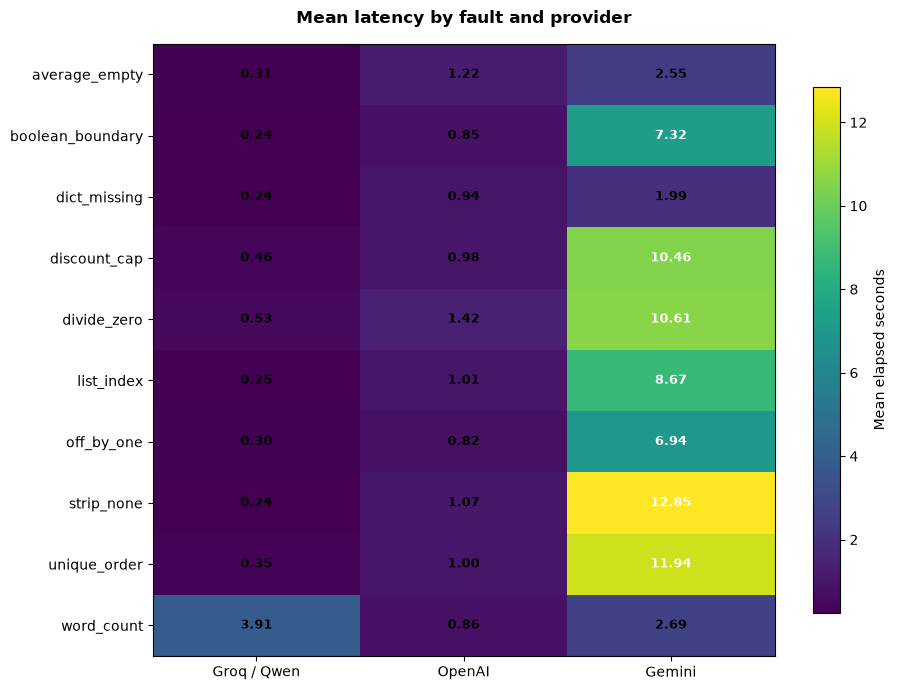

In [10]:
heat=df.pivot_table(index="case_id",columns="provider",values="elapsed_seconds",aggfunc="mean").reindex(columns=PREFERRED_ORDER)
fig,ax=plt.subplots(figsize=(9.5,7))
img=ax.imshow(heat.to_numpy(),aspect="auto",cmap="viridis")
ax.set_yticks(range(len(heat.index)),heat.index)
ax.set_xticks(range(3),[DISPLAY_NAMES[p] for p in PREFERRED_ORDER])
for i in range(len(heat.index)):
    for j in range(3):
        v=heat.iloc[i,j]
        ax.text(j,i,f"{v:.2f}",ha="center",va="center",color="white" if v>np.nanmax(heat.to_numpy())*.35 else "black",fontsize=9,fontweight="bold")
cb=fig.colorbar(img,ax=ax,shrink=.86);cb.set_label("Mean elapsed seconds")
ax.set_title("Mean latency by fault and provider",fontweight="bold",pad=15)
fig.tight_layout();fig.savefig(FIG_DIR/"08_case_provider_latency_heatmap.png",dpi=190,bbox_inches="tight")
plt.show()

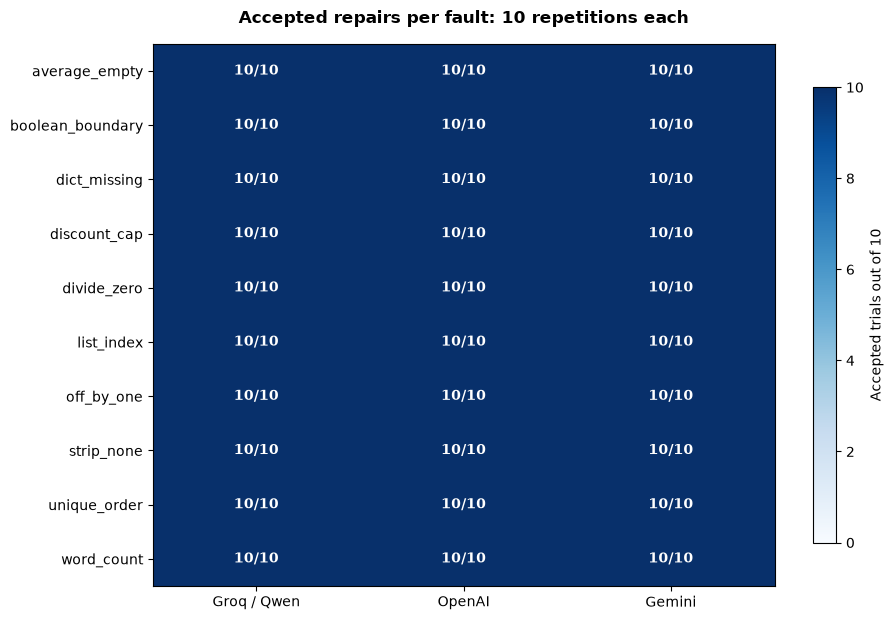

In [11]:
# Reliability matrix (number of accepted trials per provider and case)
accept=(df.assign(accepted=df.evaluation_status.eq("ACCEPTED"))
          .pivot_table(index="case_id",columns="provider",values="accepted",aggfunc="sum"))
accept=accept.reindex(index=heat.index,columns=PREFERRED_ORDER)
fig,ax=plt.subplots(figsize=(9.5,6.3))
img=ax.imshow(accept.to_numpy(),vmin=0,vmax=10,aspect="auto",cmap="Blues")
ax.set_yticks(range(len(accept.index)),accept.index)
ax.set_xticks(range(3),[DISPLAY_NAMES[p] for p in PREFERRED_ORDER])
for i in range(len(accept.index)):
    for j in range(3):ax.text(j,i,f"{int(accept.iloc[i,j])}/10",ha="center",va="center",fontweight="bold",color="white" if accept.iloc[i,j]>=7 else "black")
ax.set_title("Accepted repairs per fault: 10 repetitions each",fontweight="bold",pad=15)
fig.colorbar(img,ax=ax,shrink=.84,label="Accepted trials out of 10")
fig.tight_layout();fig.savefig(FIG_DIR/"09_case_provider_acceptance_heatmap.png",dpi=190,bbox_inches="tight")
plt.show()

## 8 · Copy-ready summary and exported assets

All nine plots are saved to `notebooks/figures/` as high-resolution PNG files suitable for inclusion in the report/PPT. A machine-readable per-provider summary CSV is also exported. Running **Restart & Run All** regenerates them from the bundled 300-row curated dataset.

In [12]:
summary_table=stats[["trials","accepted","abstained","infrastructure_errors","acceptance_pct","mean_s","median_s","p95_s","max_s","std_s","mean_attempts","total_repair_attempts","formatting_corrections","trials_with_formatting_correction"]]
summary_table.to_csv(FIG_DIR / "evaluation_provider_statistics.csv",float_format="%.6f")
display(summary_table.round(3))
print("Exported graphics:")
for file in sorted(FIG_DIR.glob("*.png")):
    print(" ",file.name)

,trials,accepted,abstained,infrastructure_errors,acceptance_pct,mean_s,median_s,p95_s,max_s,std_s,mean_attempts,total_repair_attempts,formatting_corrections,trials_with_formatting_correction
provider,,,,,,,,,,,,,,
Groq / Qwen,100,100,0,0,100.0,0.683,0.255,0.699,31.249,3.134,1.01,101,2,2
OpenAI,100,100,0,0,100.0,1.016,0.935,1.620,2.048,0.266,1.00,100,3,3
Gemini,100,100,0,0,100.0,7.602,2.498,31.806,64.497,10.987,1.00,100,61,61


Exported graphics:
  01_acceptance_by_provider.png
  02_mean_median_latency.png
  03_latency_boxplot_log.png
  04_latency_ecdf.png
  05_formatting_corrections.png
  06_repair_attempt_distribution.png
  07_accepted_risk_scores.png
  08_case_provider_latency_heatmap.png
  09_case_provider_acceptance_heatmap.png


## 9 · Results interpretation and scientific limitations

**Empirical conclusions for batch `2298cd6f`:**

- **300/300 accepted:** 100 accepted trials per provider on 10 small hand-designed Python faults, with 10 repetitions per provider/case. This measures success under the project's supplied assertions, not performance on unfamiliar real-world repositories.
- **One genuine retry:** 299 trials accepted on the first repair attempt, while one Groq `word_count` trial (trial 40) was accepted on attempt 2. The system recorded 301 repair attempts total. This is separate from scripted `recovery_demo.py` demonstrations.
- **Formatting overhead:** Gemini required **61** formatting-correction requests; OpenAI **3**, Groq **2**. They are additional formatting requests, not failed trials.
- **Latency:** Groq's 300-trial mean was approximately **0.683 s**, OpenAI **1.016 s** and Gemini **7.602 s**. Long-tail outliers and formatting overhead affect the means.
- **Risk policy:** The 300 final patches accepted by the controller had LOW risk scores under the implemented heuristic; one HIGH-risk intermediate attempt was rejected. These scores are not empirical vulnerability probabilities.

**Threats to validity:** (1) Only ten small, curated faults; (2) repeated observations from the same cases are not independent samples of real software bugs; (3) the so-called hidden assertions participate in acceptance and therefore do not constitute an untouched final holdout; (4) a passing test suite does not establish semantic correctness; (5) provider/model configuration, quotas, rate limits, network jitter and sequential ordering confound latency; (6) the process is not a secure sandbox; (7) token usage, cost, complete transient retry counts, and external vulnerability ground truth are **not available** in the supplied records and are intentionally not fabricated.

**Scope:** This notebook is an **offline analysis** of the principal experiment. The separate public BYOK reviewer performs static analysis without executing uploaded code, and should not be described as performing this local test-based acceptance workflow.

### Project demonstration

Use this notebook's first five charts to discuss measured outcomes; use the local Neon Command Center for actual controlled LLM repair and the public reviewer for non-executing proposals. Avoid claiming any self-improvement or multi-agent independence not present in the code.